# 05. Fuel Consumption Modeling — porównanie modeli i strojenie GBT

**Cel:** prognoza `fuel_kg` z porównaniem Baseline, Linear Regression, Random Forest, GBT oraz opcjonalnego XGBoost; następnie strojenie GBT na `rank` i końcowa ocena wybranego wariantu na `final`.

**Podział:** `train` = uczenie, `rank` = wybór modelu i parametrów, `final` = ocena końcowa. Zbiory nie służą do uczenia imputacji poza `train`.



In [0]:
import pyspark.sql.functions as F
from pyspark.sql.types import NumericType
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

CATALOG = "pk_big_data"
SCHEMA = "curated"
SEED = 42

def tbl(name):
    return spark.table(f"{CATALOG}.{SCHEMA}.{name}")

train_raw = tbl("fuel_segments_train")
rank_raw = tbl("fuel_segments_rank")
final_raw = tbl("fuel_segments_final")

cat_col = next((x for x in ["flight_aircraft_type", "aircraft_type"]
                if all(x in d.columns for d in [train_raw, rank_raw, final_raw])), None)
assert cat_col is not None, "Nie znaleziono kolumny typu samolotu."
for name, d in [("train", train_raw), ("rank", rank_raw), ("final", final_raw)]:
    assert all(c in d.columns for c in ["idx", "flight_id", "fuel_kg", "dur_s"]), f"Brak kolumn w {name}"
    print(name, "wiersze:", d.count())
print("Kolumna typu:", cat_col)


train wiersze: 131530
rank wiersze: 24289
final wiersze: 37456
Kolumna typu: flight_aircraft_type


## 1. Dobór cech i weryfikacja danych

Używamy wspólnych kolumn liczbowych. Wybór kolumn wymagających imputacji wykonujemy **tylko na train**: kolumny całkowicie puste lub stałe pomijamy jako cechy modelu, ale pozostają w tabelach źródłowych. Dla cech z brakami dodajemy wskaźnik braków (0/1). `NaN` i wartości nieskończone zastępujemy `null` na potrzeby obliczeń. Nie korzystamy z cech będących funkcją `fuel_kg`.

In [0]:
candidate_num = [
    "dur_s", "t_from_first_s", "route_km",
    "alt_mean", "alt_min", "alt_max", "alt_std", "alt_change",
    "gs_mean", "gs_min", "gs_max", "gs_std",
    "vr_mean", "vr_min", "vr_max", "vr_std",
    "mach_mean", "tas_mean", "cas_mean",
    "n_points", "n_acars", "n_adsb",
    "origin_airport_elevation", "destination_airport_elevation"
]
frames = [train_raw, rank_raw, final_raw]
common_nums = [c for c in candidate_num
               if all(c in d.columns and isinstance(d.schema[c].dataType, NumericType) for d in frames)]
assert "dur_s" in common_nums, "Brak numerycznej kolumny dur_s"

# Braki i statystyki rozpoznajemy jedynie w train, bez liczenia wartości z rank/final.
def clean_number(c):
    x = F.col(c).cast("double")
    return F.when(x.isNull() | F.isnan(x) | (F.abs(x) == F.lit(float("inf"))),
                  F.lit(None).cast("double")).otherwise(x)

train_clean_probe = train_raw.select(*[clean_number(c).alias(c) for c in common_nums])
probe = train_clean_probe.agg(*sum(([
    F.count(F.col(c)).alias(f"{c}__n"),
    F.min(F.col(c)).alias(f"{c}__min"),
    F.max(F.col(c)).alias(f"{c}__max")
] for c in common_nums), [])).first().asDict()
num_cols = [c for c in common_nums if probe[f"{c}__n"] > 0 and
            probe[f"{c}__min"] != probe[f"{c}__max"]]
missing_cols = [c for c in num_cols if probe[f"{c}__n"] < train_raw.count()]
assert "dur_s" in num_cols
print("Wykorzystane cechy liczbowe:", num_cols)
print("Flagi braków:", missing_cols)
print("Pominięte jako puste/stałe WYŁĄCZNIE w modelu:", sorted(set(common_nums) - set(num_cols)))


Wykorzystane cechy liczbowe: ['dur_s', 't_from_first_s', 'route_km', 'alt_mean', 'alt_min', 'alt_max', 'alt_std', 'alt_change', 'gs_mean', 'gs_min', 'gs_max', 'gs_std', 'vr_mean', 'vr_min', 'vr_max', 'vr_std', 'mach_mean', 'tas_mean', 'cas_mean', 'n_points', 'n_acars', 'n_adsb', 'origin_airport_elevation', 'destination_airport_elevation']
Flagi braków: ['alt_mean', 'alt_min', 'alt_max', 'alt_std', 'alt_change', 'gs_mean', 'gs_min', 'gs_max', 'gs_std', 'vr_mean', 'vr_min', 'vr_max', 'vr_std', 'mach_mean', 'tas_mean', 'cas_mean']
Pominięte jako puste/stałe WYŁĄCZNIE w modelu: []


## 2. Spójne przygotowanie train / rank / final

Odrzucamy wyłącznie wiersze z niepoprawnym celem lub `dur_s <= 0` (dotyczy wszystkich zbiorów i jest kontrolowane liczbowo). Dla oceny zgodnej z regułami konkursu upewnij się, że definicja kwalifikujących się przedziałów jest zgodna z docelowym zadaniem. Uzupełnianie danych i kodowanie typu samolotu są dopasowywane wyłącznie do `train`.

In [0]:
def prepare(raw):
    d = raw.filter(
        F.col("fuel_kg").isNotNull() & (F.col("fuel_kg") >= 0) &
        F.col("dur_s").isNotNull() & (F.col("dur_s") > 0)
    )
    for c in num_cols:
        d = d.withColumn(c, clean_number(c))
    for c in missing_cols:
        d = d.withColumn(f"missing_{c}", F.col(c).isNull().cast("double"))
    d = d.withColumn("aircraft_cat", F.coalesce(
        F.col(cat_col).cast("string"), F.lit("UNKNOWN")))
    return d

tr, va, te = [prepare(d) for d in frames]
for name, original, clean in [("train", train_raw, tr), ("rank", rank_raw, va), ("final", final_raw, te)]:
    print(name, "przed:", original.count(), "po kontroli:", clean.count())

# Ważne: identyczne kolumny we wszystkich zbiorach.
assert tr.columns == va.columns == te.columns or all(
    all(c in d.columns for c in num_cols + ["fuel_kg", "aircraft_cat"])
    for d in [tr, va, te]
)


train przed: 131530 po kontroli: 131530
rank przed: 24289 po kontroli: 24289
final przed: 37456 po kontroli: 37456


## 3. Baseline — średnie tempo zużycia paliwa z train

Baseline przewiduje `dur_s × (sum(fuel_kg) / sum(dur_s))`. Nie jest osobnym estymatorem Spark ML; nadaje jednak podstawowy punkt odniesienia i nie wykorzystuje danych walidacyjnych do uczenia.

In [0]:
train_totals = tr.agg(F.sum("fuel_kg").alias("fuel"), F.sum("dur_s").alias("time")).first()
BASELINE_KG_PER_S = float(train_totals["fuel"]) / float(train_totals["time"])
print("Baseline kg/h:", round(BASELINE_KG_PER_S * 3600, 2))

def baseline_predict(df):
    return df.withColumn("prediction", F.col("dur_s") * F.lit(BASELINE_KG_PER_S))

rmse_eval = RegressionEvaluator(labelCol="fuel_kg", predictionCol="prediction", metricName="rmse")
mae_eval = RegressionEvaluator(labelCol="fuel_kg", predictionCol="prediction", metricName="mae")

def evaluate(pred):
    return float(rmse_eval.evaluate(pred)), float(mae_eval.evaluate(pred))


Baseline kg/h: 3774.39


## 4. Pipeline i modele Spark ML

Dla regresji liniowej i drzew używamy `StringIndexer` + `OneHotEncoder` (brak sztucznego porządku typów). `Imputer` oblicza mediany tylko z treningu. Liczba drzew i iteracji jest rozsądna na pierwszy eksperyment; dalsze warianty należy oceniać **tylko na rank**.

In [0]:
imp_cols = ["imp_" + c for c in num_cols]
missing_flags = [f"missing_{c}" for c in missing_cols]

def preprocessing():
    return [
        Imputer(inputCols=num_cols, outputCols=imp_cols, strategy="median"),
        StringIndexer(inputCol="aircraft_cat", outputCol="aircraft_index", handleInvalid="keep"),
        OneHotEncoder(inputCols=["aircraft_index"], outputCols=["aircraft_ohe"], handleInvalid="keep"),
        VectorAssembler(inputCols=imp_cols + missing_flags + ["aircraft_ohe"],
                        outputCol="features", handleInvalid="keep")
    ]

regressors = {
    "LinearRegression": LinearRegression(featuresCol="features", labelCol="fuel_kg",
                                         predictionCol="prediction", regParam=0.1,
                                         elasticNetParam=0.0, maxIter=100),
    "RandomForest": RandomForestRegressor(featuresCol="features", labelCol="fuel_kg",
                                            predictionCol="prediction", numTrees=60,
                                            maxDepth=8, seed=SEED),
    "GBT": GBTRegressor(featuresCol="features", labelCol="fuel_kg",
                        predictionCol="prediction", maxIter=40, maxDepth=5, seed=SEED)
}
models = {}
results = []

pred_base = baseline_predict(va)
score = evaluate(pred_base)
results.append(("Baseline", *score, "ok"))
print("Baseline", score)

for name, estimator in regressors.items():
    model = Pipeline(stages=preprocessing() + [estimator]).fit(tr)
    models[name] = model
    score = evaluate(model.transform(va))
    results.append((name, *score, "ok"))
    print(name, "RMSE/MAE:", score)


Baseline (510.51949596075104, 283.3059410466428)
LinearRegression RMSE/MAE: (376.8021803889021, 176.21753109747215)
RandomForest RMSE/MAE: (284.86285359952785, 107.77395025964387)
GBT RMSE/MAE: (271.86748876300896, 94.22871998183359)


## 5. Porównanie modeli na `rank` i wybór zwycięzcy

**Jedynym kryterium wyboru jest najniższy RMSE na rank**; MAE raportujemy dodatkowo. `final` pozostaje nietknięty aż do wyboru modelu. Brak wyniku XGBoost nie jest traktowany jak porażka predykcyjna, lecz jako problem dostępności/uruchomienia.

In [0]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType
result_schema = StructType([
    StructField("model_name", StringType()),
    StructField("rmse_kg", DoubleType()),
    StructField("mae_kg", DoubleType()),
    StructField("status", StringType())
])
rank_summary = spark.createDataFrame(results, schema=result_schema).orderBy("rmse_kg")
display(rank_summary)
valid_results = [x for x in results if x[3] == "ok"]
assert valid_results, "Nie udało się ocenić żadnego modelu"
best_name, best_rmse, best_mae, _ = min(valid_results, key=lambda x: x[1])
print("Wybrany model wg RMSE rank:", best_name, best_rmse, "kg")

def predict_best(df):
    return baseline_predict(df) if best_name == "Baseline" else models[best_name].transform(df)

pred_rank = predict_best(va)


model_name,rmse_kg,mae_kg,status
GBT,271.86748876300896,94.22871998183359,ok
RandomForest,284.86285359952785,107.77395025964387,ok
LinearRegression,376.8021803889021,176.21753109747215,ok
Baseline,510.51949596075104,283.3059410466428,ok


Wybrany model wg RMSE rank: GBT 271.86748876300896 kg


## 6. Strojenie hiperparametrów GBT na `rank`

Po porównaniu wszystkich modeli sprawdzamy dziewięć konfiguracji GBT: `maxDepth` = 3/5/7 i `maxIter` = 25/40/70 (`stepSize` = 0.1). Uwzględniamy konfigurację bazową 5/40. **Wszystkie modele są dopasowywane tylko do `train`**, a `rank` służy wyłącznie do wyboru ustawień. Jeżeli XGBoost lub inny model z poprzedniego porównania uzyska niższy RMSE niż dostrojony GBT, pozostawiamy go jako ostatecznego zwycięzcę.


In [0]:
from itertools import product
from pyspark import StorageLevel
from pyspark.ml.regression import GBTRegressor
from pyspark.sql.types import IntegerType
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


gbt_pipeline = models["GBT"]
from pyspark.ml import PipelineModel
preprocessor = PipelineModel(stages=gbt_pipeline.stages[:-1])
train_vec = preprocessor.transform(tr).select("features", "fuel_kg").persist(StorageLevel.MEMORY_AND_DISK)
rank_vec = preprocessor.transform(va).select("features", "fuel_kg").persist(StorageLevel.MEMORY_AND_DISK)
print("Train for tuning:", train_vec.count(), "| Rank for tuning:", rank_vec.count())

param_grid = sorted(product([3, 5, 7], [25, 40, 70]), key=lambda p: (p != (5, 40), p))
tuning_rows = []
best_gbt_model = None
best_gbt_params = None
best_gbt_rmse = float("inf")
best_gbt_mae = None
for i, (depth, iterations) in enumerate(param_grid, 1):
    print(f"[{i}/9] GBT maxDepth={depth}, maxIter={iterations}")
    estimator = GBTRegressor(featuresCol="features", labelCol="fuel_kg",
                             predictionCol="prediction", maxDepth=depth,
                             maxIter=iterations, stepSize=0.1, seed=SEED)
    fitted = estimator.fit(train_vec)
    rmse, mae = evaluate(fitted.transform(rank_vec))
    tuning_rows.append((int(depth), int(iterations), float(0.1), rmse, mae))
    print(f"   RANK RMSE = {rmse:.3f} kg, MAE = {mae:.3f} kg")
    if rmse < best_gbt_rmse:
        best_gbt_model, best_gbt_params = fitted, (depth, iterations)
        best_gbt_rmse, best_gbt_mae = rmse, mae

tuning_schema = StructType([
    StructField("max_depth", IntegerType()),
    StructField("max_iter", IntegerType()),
    StructField("step_size", DoubleType()),
    StructField("rmse_kg", DoubleType()),
    StructField("mae_kg", DoubleType())
])
tuning_df = spark.createDataFrame(tuning_rows, schema=tuning_schema).orderBy("rmse_kg")
display(tuning_df)
print("GBT best rank:", best_gbt_params, round(best_gbt_rmse, 3), "kg")

initial_best_name, initial_best_rmse, initial_best_mae = best_name, best_rmse, best_mae
initial_gbt_rmse = next(x[1] for x in results if x[0] == "GBT" and x[3] == "ok")
initial_gbt_mae = next(x[2] for x in results if x[0] == "GBT" and x[3] == "ok")
use_tuned_gbt = best_gbt_rmse < initial_best_rmse
if use_tuned_gbt:
    best_name, best_rmse, best_mae = "GBT_tuned", best_gbt_rmse, best_gbt_mae

def predict_selected(df):
    if best_name == "GBT_tuned":
        return best_gbt_model.transform(preprocessor.transform(df))
    return baseline_predict(df) if best_name == "Baseline" else models[best_name].transform(df)

results_extended = list(results) + [("GBT_tuned", best_gbt_rmse, best_gbt_mae, "ok")]
rank_summary = spark.createDataFrame(results_extended, schema=result_schema).orderBy("rmse_kg")
display(rank_summary)
print("Final selected by RANK:", best_name, "RMSE:", round(best_rmse, 3))


Train for tuning: 131530 | Rank for tuning: 24289
[1/9] GBT maxDepth=5, maxIter=40
   RANK RMSE = 271.867 kg, MAE = 94.229 kg
[2/9] GBT maxDepth=3, maxIter=25
   RANK RMSE = 292.737 kg, MAE = 114.714 kg
[3/9] GBT maxDepth=3, maxIter=40
   RANK RMSE = 281.547 kg, MAE = 105.258 kg
[4/9] GBT maxDepth=3, maxIter=70
   RANK RMSE = 272.453 kg, MAE = 98.030 kg
[5/9] GBT maxDepth=5, maxIter=25
   RANK RMSE = 275.622 kg, MAE = 97.096 kg
[6/9] GBT maxDepth=5, maxIter=70
   RANK RMSE = 268.811 kg, MAE = 91.526 kg
[7/9] GBT maxDepth=7, maxIter=25
   RANK RMSE = 292.448 kg, MAE = 93.286 kg
[8/9] GBT maxDepth=7, maxIter=40
   RANK RMSE = 290.916 kg, MAE = 91.684 kg
[9/9] GBT maxDepth=7, maxIter=70
   RANK RMSE = 291.959 kg, MAE = 89.808 kg


max_depth,max_iter,step_size,rmse_kg,mae_kg
5,70,0.1,268.810911505848,91.5256018160183
5,40,0.1,271.86748876300896,94.22871998183359
3,70,0.1,272.45333467977304,98.03046020337473
5,25,0.1,275.6220301643952,97.09649949576472
3,40,0.1,281.5468032501852,105.25753852451393
7,40,0.1,290.91612775054995,91.68393900314774
7,70,0.1,291.9587961921271,89.80847199179749
7,25,0.1,292.4484739143971,93.28624349001424
3,25,0.1,292.7371138073621,114.71360593199113


GBT best rank: (5, 70) 268.811 kg


model_name,rmse_kg,mae_kg,status
GBT_tuned,268.810911505848,91.5256018160183,ok
GBT,271.86748876300896,94.22871998183359,ok
RandomForest,284.86285359952785,107.77395025964387,ok
LinearRegression,376.8021803889021,176.21753109747215,ok
Baseline,510.51949596075104,283.3059410466428,ok


Final selected by RANK: GBT_tuned RMSE: 268.811


## 7. Wizualizacje strojenia GBT

Wykresy RMSE i MAE dla poszczególnych konfiguracji oraz mapa cieplna RMSE. Przerywana linia pokazuje wyniki **wcześniejszego GBT obliczone podczas tego samego uruchomienia notebooka**.


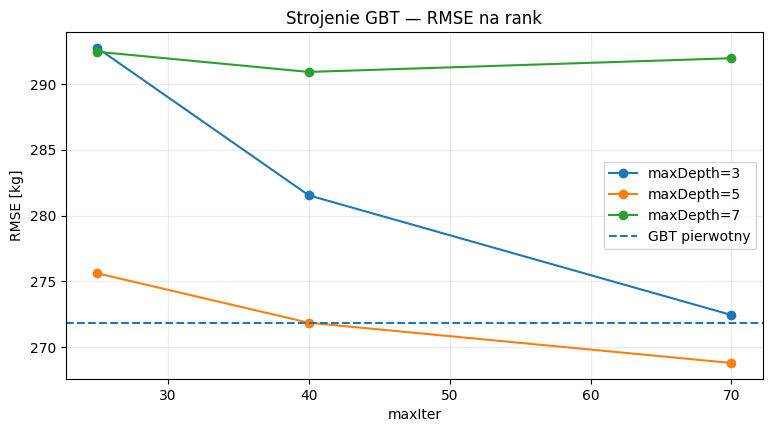

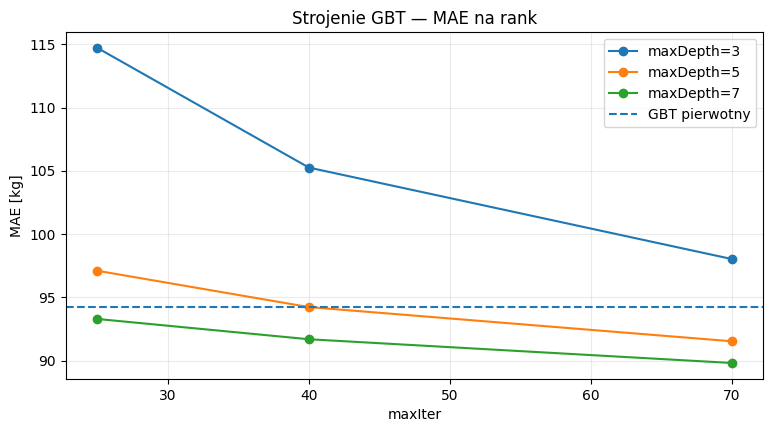

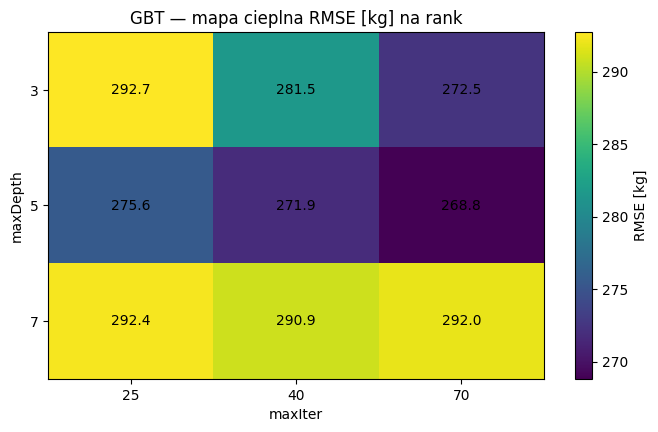

In [0]:
tuning_pd = pd.DataFrame(tuning_rows, columns=["max_depth", "max_iter", "step_size", "rmse_kg", "mae_kg"])
for metric, label in [("rmse_kg", "RMSE"), ("mae_kg", "MAE")]:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for depth in sorted(tuning_pd.max_depth.unique()):
        part = tuning_pd[tuning_pd.max_depth == depth].sort_values("max_iter")
        ax.plot(part.max_iter, part[metric], marker="o", label=f"maxDepth={depth}")
    ax.axhline(initial_gbt_rmse if metric == "rmse_kg" else initial_gbt_mae,
               linestyle="--", label="GBT pierwotny")
    ax.set(xlabel="maxIter", ylabel=f"{label} [kg]", title=f"Strojenie GBT — {label} na rank")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

pivot = tuning_pd.pivot(index="max_depth", columns="max_iter", values="rmse_kg")
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(pivot.to_numpy(), aspect="auto")
ax.set_xticks(range(len(pivot.columns)), labels=[str(x) for x in pivot.columns])
ax.set_yticks(range(len(pivot.index)), labels=[str(x) for x in pivot.index])
ax.set(xlabel="maxIter", ylabel="maxDepth", title="GBT — mapa cieplna RMSE [kg] na rank")
for r in range(len(pivot.index)):
    for c in range(len(pivot.columns)):
        ax.text(c, r, f"{pivot.iloc[r, c]:.1f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="RMSE [kg]")
plt.show()


## 8. Diagnostyka wybranego modelu na `rank`

Przed oceną na `final` sprawdzamy rozkład błędów według długości przedziału, typów samolotów (co najmniej 30 przedziałów), wartości zużycia paliwa, a także ewentualne ujemne predykcje. Są to **błędy bezwzględne w kilogramach**, zatem większe błędy w grupie większego spalania nie muszą oznaczać większych błędów procentowych.


duration_group,n,mae_kg,rmse_kg
5–60 min,13740,122.90111550939356,340.32800385796173
<5 min,10549,50.65921086455523,124.57005519091045


flight_aircraft_type,n,mae_kg,rmse_kg
A20N,11989,41.982301798081245,87.93146910171492
A320,4993,50.31233284236946,88.63898966727626
A359,3578,179.7007714698843,412.99918898958776
A332,805,238.80538282439016,561.8717627107495
B789,630,152.27870448232812,289.8661048953819
B738,585,63.27620577004154,100.4889966734571
B788,387,266.9383947510938,417.82422380139906
B77W,318,468.19914296850266,895.2768610392725
B744,240,731.8100843795254,1212.7572633611833
A333,191,139.22326769415412,224.9575437704099


fuel_group,n,mae_kg,rmse_kg
100–499 kg,10441,57.36894077168149,98.98250792555997
500–1999 kg,3752,214.92628653055513,355.16200053386143
<100 kg,9185,25.385136462101478,44.32480029723983
≥2000 kg,911,641.6139697531161,1129.1405525551224


Negative rank fuel predictions: 131


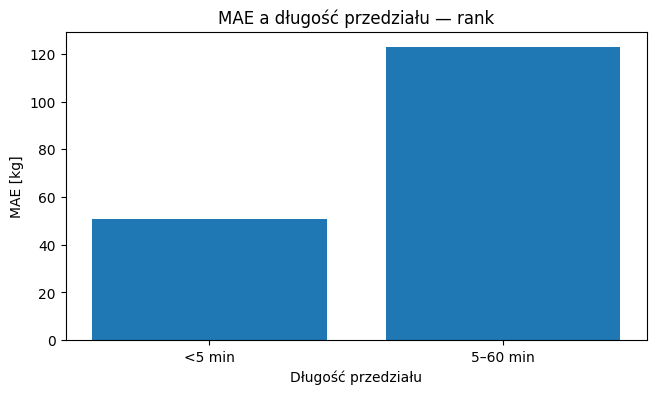

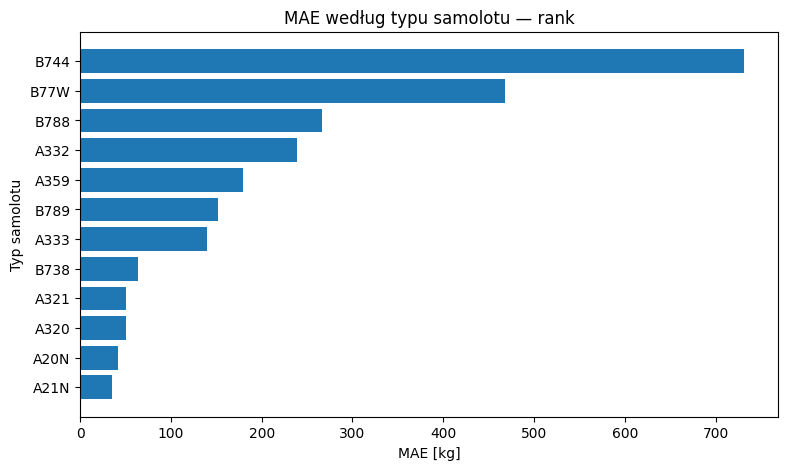

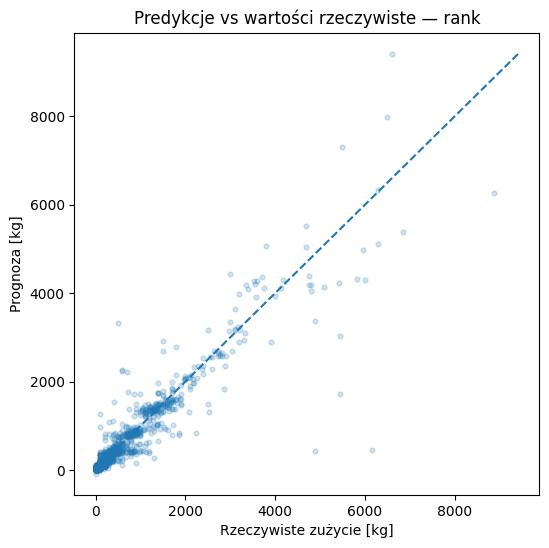

In [0]:
pred_rank = predict_selected(va)
rank_rmse, rank_mae = evaluate(pred_rank)
pred_rank = pred_rank.withColumn("abs_error", F.abs(F.col("prediction") - F.col("fuel_kg"))) \
    .withColumn("squared_error", F.pow(F.col("prediction") - F.col("fuel_kg"), 2))

def grouped_error(df, group):
    return df.groupBy(group).agg(F.count("*").alias("n"),
           F.avg("abs_error").alias("mae_kg"),
           F.sqrt(F.avg("squared_error")).alias("rmse_kg"))

rank_by_duration = grouped_error(pred_rank.withColumn(
    "duration_group", F.when(F.col("dur_s") < 300, "<5 min")
                       .when(F.col("dur_s") <= 3600, "5–60 min")
                       .otherwise(">60 min")), "duration_group")
rank_by_aircraft = grouped_error(pred_rank, cat_col).filter(F.col("n") >= 30)
rank_by_fuel = grouped_error(pred_rank.withColumn(
    "fuel_group", F.when(F.col("fuel_kg") < 100, "<100 kg")
                   .when(F.col("fuel_kg") < 500, "100–499 kg")
                   .when(F.col("fuel_kg") < 2000, "500–1999 kg")
                   .otherwise("≥2000 kg")), "fuel_group")
negative_rank = pred_rank.filter(F.col("prediction") < 0).count()
display(rank_by_duration.orderBy("duration_group"))
display(rank_by_aircraft.orderBy(F.desc("n")))
display(rank_by_fuel.orderBy("fuel_group"))
print("Negative rank fuel predictions:", negative_rank)

rank_duration_pd = rank_by_duration.toPandas()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(rank_duration_pd["duration_group"], rank_duration_pd["mae_kg"])
ax.set(xlabel="Długość przedziału", ylabel="MAE [kg]", title="MAE a długość przedziału — rank")
plt.show()

air_pd = rank_by_aircraft.orderBy(F.desc("n")).limit(12).toPandas().sort_values("mae_kg")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(air_pd[cat_col], air_pd["mae_kg"])
ax.set(xlabel="MAE [kg]", ylabel="Typ samolotu", title="MAE według typu samolotu — rank")
plt.show()

sample_pd = pred_rank.select("fuel_kg", "prediction").sample(False, 0.1, seed=SEED).limit(2500).toPandas()
if len(sample_pd) > 0:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(sample_pd["fuel_kg"], sample_pd["prediction"], alpha=0.2, s=12)
    max_axis = max(float(sample_pd["fuel_kg"].max()), float(sample_pd["prediction"].max()), 1.0)
    ax.plot([0, max_axis], [0, max_axis], linestyle="--")
    ax.set(xlabel="Rzeczywiste zużycie [kg]", ylabel="Prognoza [kg]", title="Predykcje vs wartości rzeczywiste — rank")
    plt.show()


## 9. Ocena końcowa wybranego modelu na `final`

**Dopiero teraz** uruchamiamy ocenę na `final`. Konfiguracja została wybrana na `rank`; nie zmieniamy jej według otrzymanego RMSE `final`. Wartości wcześniejszego GBT dla `final` są znane z poprzedniego eksperymentu i służą wyłącznie jako punkt odniesienia, **nie do wyboru konfiguracji**.


In [0]:
pred_final = predict_selected(te)
final_rmse, final_mae = evaluate(pred_final)
print(f"FINAL — {best_name}: RMSE={final_rmse:.3f} kg | MAE={final_mae:.3f} kg")


comparison_df = spark.createDataFrame([
    ("Wybrany model final", rank_rmse, rank_mae, final_rmse, final_mae),
], schema="wariant string, rank_rmse_kg double, rank_mae_kg double, final_rmse_kg double, final_mae_kg double")
display(comparison_df)


FINAL — GBT_tuned: RMSE=252.066 kg | MAE=86.739 kg


wariant,rank_rmse_kg,rank_mae_kg,final_rmse_kg,final_mae_kg
Wybrany model final,268.810911505848,91.5256018160183,252.0656526854556,86.73878231462275


## 10. Wizualizacja przed i po strojeniu

Porównujemy GBT przed strojeniem i najlepszy GBT na `rank`. Jeżeli dostrojony GBT nie wygrał z innym algorytmem, na `final` pokazujemy wyłącznie wynik rzeczywiście wybranego modelu (nie wykonujemy niepotrzebnych ocen wszystkich kandydatów).


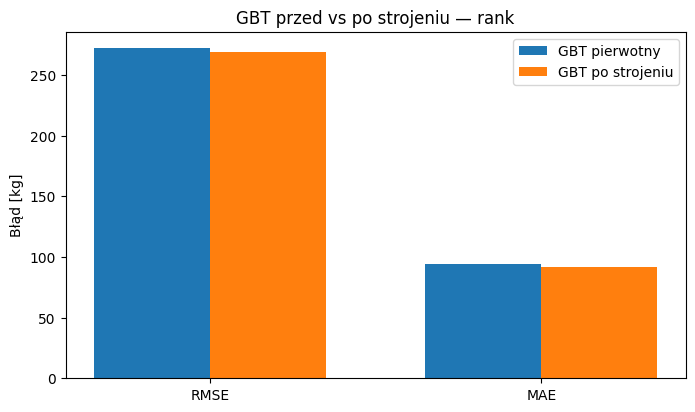

In [0]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
w = 0.35
ax.bar(x - w/2, [initial_gbt_rmse, initial_gbt_mae], width=w, label="GBT pierwotny")
ax.bar(x + w/2, [best_gbt_rmse, best_gbt_mae], width=w, label="GBT po strojeniu")
ax.set_xticks(x, ["RMSE", "MAE"])
ax.set(ylabel="Błąd [kg]", title="GBT przed vs po strojeniu — rank")
ax.legend()
plt.show()


## 11. Zapis wyników do Delta — zgodność z notebookiem 06

Zapisujemy predykcje wybranego modelu dla `rank` i `final`, porównanie wszystkich algorytmów oraz dziewięć konfiguracji GBT. Operacje `overwrite` zastępują istniejące tabele wynikowe, **nie zmieniają danych źródłowych**.


In [0]:
def save_predictions(pred, phase):
    selected = ["idx", "flight_id", "fuel_kg", "prediction"]
    selected += [c for c in ["dur_s", "route_km", cat_col] if c in pred.columns]
    d = (pred.select(*selected)
         .withColumn("model_name", F.lit(best_name))
         .withColumn("predicted_co2_kg", F.greatest(F.col("prediction"), F.lit(0.0)) * F.lit(3.16))
         .withColumn("actual_co2_kg", F.col("fuel_kg") * F.lit(3.16)))
    d.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(
        f"{CATALOG}.{SCHEMA}.fuel_predictions_{phase}")

save_predictions(pred_rank, "rank")
save_predictions(pred_final, "final")
rank_summary.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(
    f"{CATALOG}.{SCHEMA}.fuel_model_rank_metrics")
final_summary = spark.createDataFrame([(best_name, final_rmse, final_mae, "ok")], schema=result_schema)
final_summary.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(
    f"{CATALOG}.{SCHEMA}.fuel_model_final_metrics")
tuning_df.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(
    f"{CATALOG}.{SCHEMA}.fuel_gbt_tuning_rank")
train_vec.unpersist()
rank_vec.unpersist()
print("Zapisano predykcje, metryki i historię strojenia do tabel Delta.")


Zapisano predykcje, metryki i historię strojenia do tabel Delta.


## 12. Wnioski z modelowania zużycia paliwa

### 12.1. Wybór modelu predykcyjnego

Celem modelowania było przewidywanie zużycia paliwa (`fuel_kg`) dla poszczególnych przedziałów lotu na podstawie typu samolotu, parametrów trajektorii oraz charakterystyki operacyjnej lotu.

W ramach eksperymentów porównano cztery podejścia:
- Model referencyjny (Baseline).
- Regresję liniową (Linear Regression).
- Random Forest Regressor.
- Gradient Boosted Trees (GBT).

Na podstawie oceny na zbiorze rankingowym (`rank`) wybrano Gradient Boosted Trees jako najlepszy spośród przetestowanych algorytmów.

Następnie przeprowadzono strojenie hiperparametrów GBT. Przetestowano dziewięć konfiguracji różniących się maksymalną głębokością drzew oraz liczbą iteracji.

Wybrana konfiguracja modelu:

| Hiperparametr | Wartość |
|---|---:|
| `maxDepth` | 5 |
| `maxIter` | 70 |
| `stepSize` | 0,1 |

Zbiór `rank` wykorzystano do wyboru konfiguracji, a zbiór `final` do końcowej oceny wybranego modelu.

### 12.2. Wyniki modelu na zbiorze testowym

Końcową ocenę dostrojonego modelu GBT przeprowadzono na zbiorze `final`, obejmującym **37 456 przedziałów lotu**.

| Metryka | Wynik |
|---|---:|
| RMSE | **252,07 kg** |
| MAE | **86,74 kg** |

Uzyskana wartość MAE oznacza, że przewidywane zużycie paliwa różniło się od wartości rzeczywistej średnio o **86,74 kg na przedział lotu**, licząc błąd bezwzględny.

Wartość RMSE wyniosła **252,07 kg** i była wyraźnie wyższa od MAE. Wskazuje to, że wśród predykcji występowały również obserwacje o stosunkowo dużych błędach, które silniej wpływają na RMSE.

Otrzymane wyniki pokazują, że model jest w stanie odtwarzać zależności między charakterystyką lotu a zużyciem paliwa, jednak dokładność prognoz pozostaje zróżnicowana.

### 12.3. Znaczenie strojenia hiperparametrów

Strojenie GBT umożliwiło wybranie konfiguracji na podstawie systematycznego porównania różnych głębokości drzew oraz liczby iteracji.

Zastosowanie zbioru rankingowego pozwoliło oddzielić proces wyboru modelu od jego końcowej oceny.

Wybrany model wykorzystuje 70 iteracji i maksymalną głębokość drzew równą 5.

Dzięki temu końcowa konfiguracja nie została wybrana arbitralnie, lecz na podstawie przyjętej procedury walidacyjnej.

### 12.4. Znaczenie danych opisujących lot

W modelowaniu wykorzystano cechy należące do kilku grup:
- Czas trwania i położenie przedziału w locie.
- Typ samolotu.
- Charakterystyka trasy.
- Wysokość lotu oraz jej zmiany.
- Parametry prędkości poziomej i pionowej.
- Informacje o dostępności i liczbie punktów pomiarowych.

Zastosowanie modelu GBT umożliwiło uwzględnienie nieliniowych zależności pomiędzy tymi cechami a zużyciem paliwa.

Istotnym elementem przygotowania danych była również obsługa brakujących wartości. Dzięki temu możliwe było wykorzystanie obserwacji, dla których nie wszystkie parametry trajektorii były dostępne.

Same wyniki predykcyjne nie pozwalają jednak określić, które cechy miały największy wpływ na decyzje modelu.

### 12.5. Ograniczenia analizy

Otrzymane wyniki należy interpretować z uwzględnieniem kilku ograniczeń.

Po pierwsze, model przewiduje zużycie paliwa dla **pojedynczych przedziałów**, a nie dla całych lotów.

Po drugie, zbiór obejmuje samoloty o różnych rozmiarach, charakterystykach operacyjnych i liczebnościach obserwacji. Ogólne wartości RMSE i MAE nie oznaczają zatem jednakowej dokładności dla każdego typu samolotu.

Po trzecie, nie wszystkie czynniki wpływające na zużycie paliwa były dostępne w danych, w szczególności rzeczywista masa samolotu, obciążenie pasażerami oraz pełne warunki meteorologiczne.

Dodatkowo wyższa wartość RMSE w porównaniu z MAE wskazuje na potrzebę zachowania ostrożności przy interpretowaniu pojedynczych predykcji, szczególnie w przypadku przedziałów o dużym zużyciu paliwa.

### 12.6. Wniosek końcowy

W ramach analizy zbudowano i porównano modele uczenia maszynowego służące do przewidywania zużycia paliwa na podstawie charakterystyki samolotu i parametrów lotu.

Spośród przetestowanych algorytmów wybrano Gradient Boosted Trees, którego hiperparametry dostrojono na zbiorze rankingowym.

**Ostateczny model GBT osiągnął na zbiorze testowym RMSE = 252,07 kg oraz MAE = 86,74 kg.**

Wyniki wskazują, że wykorzystanie metod opartych na drzewach decyzyjnych umożliwia modelowanie złożonych zależności pomiędzy parametrami lotu a zużyciem paliwa.

Jednocześnie różnica między RMSE i MAE pokazuje, że dokładność prognoz jest zróżnicowana, a część obserwacji charakteryzuje się większym błędem.

**Główny wniosek:** dostrojony model GBT stanowi wybrany model predykcyjny projektu i pozwala szacować zużycie paliwa dla obserwowanych przedziałów lotu. Uzyskane predykcje mogą również stanowić podstawę do szacowania emisji CO₂, przy zachowaniu świadomości ograniczeń dokładności modelu.
